# Crypto Market Data ETL Pipeline
Gets live crypto prices from the CoinPaprika API and stores them in a SQLite database.

**Extract -> Validate -> Transform -> Model -> Load -> Visualize**

## 1. Import libraries

In [1]:
import os
import sqlite3
import logging
from datetime import datetime
import requests
import pandas as pd
import matplotlib.pyplot as plt

## 2. Logging
Save messages with the time into `pipeline.log`.

In [2]:
logging.basicConfig(filename="pipeline.log", level=logging.INFO,
                    format="%(asctime)s - %(levelname)s - %(message)s", force=True)
logging.getLogger("matplotlib").setLevel(logging.WARNING)   # keep matplotlib messages out of our log
logging.info("Pipeline started")
print("Logging is ready")

Logging is ready


## 3. Extract
Call the API for 5 coins. Status code 200 means it worked.

In [3]:
coin_ids = ["btc-bitcoin", "eth-ethereum", "xrp-xrp", "sol-solana", "doge-dogecoin"]

raw_coin_data = []
for coin_id in coin_ids:
    response = requests.get("https://api.coinpaprika.com/v1/tickers/" + coin_id, timeout=10)
    if response.status_code == 200:
        raw_coin_data.append(response.json())   # JSON -> Python dictionary
    else:
        logging.error("API failed for " + coin_id)

print("Extracted", len(raw_coin_data), "coins")
logging.info("Extracted " + str(len(raw_coin_data)) + " coins")

Extracted 5 coins


Raw JSON for one coin. The price is inside `quotes -> USD`.

In [4]:
raw_coin_data[0]

{'id': 'btc-bitcoin',
 'name': 'Bitcoin',
 'symbol': 'BTC',
 'rank': 1,
 'total_supply': 20104675,
 'max_supply': 21000000,
 'beta_value': 1.04858,
 'first_data_at': '2010-07-17T00:00:00Z',
 'last_updated': '2026-10-28T04:59:17Z',
 'quotes': {'USD': {'price': 80885.08799635638,
   'volume_24h': 18115431566.604404,
   'volume_24h_change_24h': -12.210000038146973,
   'market_cap': 1626169134478,
   'market_cap_change_24h': 1.2899999618530273,
   'percent_change_15m': 0.009999999776482582,
   'percent_change_30m': -0.09000000357627869,
   'percent_change_1h': -0.009999999776482582,
   'percent_change_6h': 0.09000000357627869,
   'percent_change_12h': 0.4099999964237213,
   'percent_change_24h': 1.2899999618530273,
   'percent_change_7d': -2.049999952316284,
   'percent_change_30d': 0,
   'percent_change_1y': 0,
   'ath_price': 126173.1777846797,
   'ath_date': '2025-10-06T19:00:40Z',
   'percent_from_price_ath': -35.92}}}

Take out the fields we need and make a table.

In [5]:
rows = []
for coin in raw_coin_data:
    usd = coin["quotes"]["USD"]
    rows.append({"id": coin["id"], "name": coin["name"], "symbol": coin["symbol"], "rank": coin["rank"],
                 "price": usd["price"], "volume_24h": usd["volume_24h"],
                 "market_cap": usd["market_cap"], "percent_change_24h": usd["percent_change_24h"]})

raw_df = pd.DataFrame(rows)
raw_df

,id,name,symbol,rank,price,volume_24h,market_cap,percent_change_24h
0,btc-bitcoin,Bitcoin,BTC,1,80885.087996,1.811543e+10,1626169134478,1.29
1,eth-ethereum,Ethereum,ETH,2,2352.843610,7.136343e+09,287447294408,1.69
2,xrp-xrp,XRP,XRP,5,1.327901,1.133815e+09,84124129767,2.01
3,sol-solana,Solana,SOL,7,101.939924,1.325871e+09,60137266399,1.83
4,doge-dogecoin,Dogecoin,DOGE,12,0.079620,4.368102e+08,13649767419,2.66


## 4. Validate
Check for missing values, duplicates, bad prices and data types, and remove bad rows.

In [6]:
print("Missing values:", raw_df.isnull().sum().sum())
print("Duplicate coins:", raw_df.duplicated(subset="id").sum())
print("Zero or negative prices:", (raw_df["price"] <= 0).sum())

raw_df = raw_df.dropna()                      # remove rows with missing values
raw_df = raw_df.drop_duplicates(subset="id")  # remove duplicate coins
raw_df = raw_df[raw_df["price"] > 0]          # keep only prices above 0

print()
print(raw_df.dtypes)   # numbers should be int64 or float64
print()
print(len(raw_df), "coins passed validation")
logging.info(str(len(raw_df)) + " coins passed validation")

Missing values: 0
Duplicate coins: 0
Zero or negative prices: 0

id                        str
name                      str
symbol                    str
rank                    int64
price                 float64
volume_24h            float64
market_cap              int64
percent_change_24h    float64
dtype: object

5 coins passed validation


## 5. Transform
Rename columns, round numbers, add a timestamp.

In [7]:
clean_df = raw_df.rename(columns={"id": "coin_id", "price": "price_usd"})

clean_df["price_usd"] = clean_df["price_usd"].round(4)
clean_df["volume_24h"] = clean_df["volume_24h"].round(0).astype(int)
clean_df["market_cap"] = clean_df["market_cap"].round(0).astype(int)
clean_df["percent_change_24h"] = clean_df["percent_change_24h"].round(2)

now = datetime.now()
clean_df["extracted_at"] = now.strftime("%Y-%m-%d %H:%M:%S")

clean_df = clean_df.sort_values("rank").reset_index(drop=True)
logging.info("Transformed " + str(len(clean_df)) + " rows")
clean_df

,coin_id,name,symbol,rank,price_usd,volume_24h,market_cap,percent_change_24h,extracted_at
0,btc-bitcoin,Bitcoin,BTC,1,80885.0880,18115431567,1626169134478,1.29,2026-10-28 10:29:50
1,eth-ethereum,Ethereum,ETH,2,2352.8436,7136343441,287447294408,1.69,2026-10-28 10:29:50
2,xrp-xrp,XRP,XRP,5,1.3279,1133815087,84124129767,2.01,2026-10-28 10:29:50
3,sol-solana,Solana,SOL,7,101.9399,1325871160,60137266399,1.83,2026-10-28 10:29:50
4,doge-dogecoin,Dogecoin,DOGE,12,0.0796,436810222,13649767419,2.66,2026-10-28 10:29:50


## 6. Model (star schema)
**Fact table** = the numbers (prices). **Dimension tables** = the details (coin, date).

In [8]:
date_id = int(now.strftime("%Y%m%d%H%M"))   # e.g. 202610281430

dim_coin = clean_df[["coin_id", "name", "symbol"]]

dim_date = pd.DataFrame({"date_id": [date_id], "date": [now.strftime("%Y-%m-%d")],
                         "hour": [now.hour], "day_name": [now.strftime("%A")]})

fact_prices = clean_df[["coin_id", "price_usd", "volume_24h", "market_cap", "percent_change_24h"]].copy()
fact_prices.insert(1, "date_id", date_id)   # put date_id as the 2nd column

print("dim_coin:", len(dim_coin), "rows | dim_date:", len(dim_date), "row | fact_prices:", len(fact_prices), "rows")
fact_prices

dim_coin: 5 rows | dim_date: 1 row | fact_prices: 5 rows


,coin_id,date_id,price_usd,volume_24h,market_cap,percent_change_24h
0,btc-bitcoin,202610281029,80885.0880,18115431567,1626169134478,1.29
1,eth-ethereum,202610281029,2352.8436,7136343441,287447294408,1.69
2,xrp-xrp,202610281029,1.3279,1133815087,84124129767,2.01
3,sol-solana,202610281029,101.9399,1325871160,60137266399,1.83
4,doge-dogecoin,202610281029,0.0796,436810222,13649767419,2.66


## 7. Load
Save to `crypto.db`. A **primary key** plus `INSERT OR IGNORE` means no duplicates when we run again.

In [9]:
connection = sqlite3.connect("crypto.db")
cursor = connection.cursor()

cursor.execute("CREATE TABLE IF NOT EXISTS dim_coin (coin_id TEXT PRIMARY KEY, name TEXT, symbol TEXT)")
cursor.execute("CREATE TABLE IF NOT EXISTS dim_date (date_id INTEGER PRIMARY KEY, date TEXT, hour INTEGER, day_name TEXT)")
cursor.execute('''CREATE TABLE IF NOT EXISTS fact_prices (
                    coin_id TEXT, date_id INTEGER, price_usd REAL, volume_24h INTEGER,
                    market_cap INTEGER, percent_change_24h REAL,
                    PRIMARY KEY (coin_id, date_id))''')

rows_before = cursor.execute("SELECT COUNT(*) FROM fact_prices").fetchone()[0]

cursor.executemany("INSERT OR IGNORE INTO dim_coin VALUES (?, ?, ?)", dim_coin.values.tolist())
cursor.executemany("INSERT OR IGNORE INTO dim_date VALUES (?, ?, ?, ?)", dim_date.values.tolist())
cursor.executemany("INSERT OR IGNORE INTO fact_prices VALUES (?, ?, ?, ?, ?, ?)", fact_prices.values.tolist())
connection.commit()

rows_after = cursor.execute("SELECT COUNT(*) FROM fact_prices").fetchone()[0]
print("New rows added:", rows_after - rows_before, "| Total rows in fact_prices:", rows_after)
logging.info("Loaded " + str(rows_after - rows_before) + " new rows into crypto.db")

New rows added: 5 | Total rows in fact_prices: 10


## 8. Check with SQL
Top 3 coins by market cap (join fact with dim_coin).

In [10]:
query = '''SELECT c.name, f.price_usd, f.market_cap
           FROM fact_prices f JOIN dim_coin c ON f.coin_id = c.coin_id
           WHERE f.date_id = ''' + str(date_id) + '''
           ORDER BY f.market_cap DESC LIMIT 3'''
pd.read_sql_query(query, connection)

,name,price_usd,market_cap
0,Bitcoin,80885.0880,1626169134478
1,Ethereum,2352.8436,287447294408
2,XRP,1.3279,84124129767


Join all 3 tables: biggest gainers first.

In [11]:
query = '''SELECT c.name, d.date, d.day_name, f.percent_change_24h
           FROM fact_prices f
           JOIN dim_coin c ON f.coin_id = c.coin_id
           JOIN dim_date d ON f.date_id = d.date_id
           WHERE f.date_id = ''' + str(date_id) + '''
           ORDER BY f.percent_change_24h DESC'''
pd.read_sql_query(query, connection)

,name,date,day_name,percent_change_24h
0,Dogecoin,2026-10-28,Wednesday,2.66
1,XRP,2026-10-28,Wednesday,2.01
2,Solana,2026-10-28,Wednesday,1.83
3,Ethereum,2026-10-28,Wednesday,1.69
4,Bitcoin,2026-10-28,Wednesday,1.29


Average price of each coin over all runs.

In [12]:
query = '''SELECT c.symbol, COUNT(*) AS runs, AVG(f.price_usd) AS avg_price
           FROM fact_prices f JOIN dim_coin c ON f.coin_id = c.coin_id
           GROUP BY c.symbol ORDER BY avg_price DESC'''
pd.read_sql_query(query, connection)

,symbol,runs,avg_price
0,BTC,2,80871.02065
1,ETH,2,2352.62655
2,SOL,2,101.93990
3,XRP,2,1.32790
4,DOGE,2,0.07960


## 9. Visualize
Price of each coin. Log scale, so small and big prices both show.

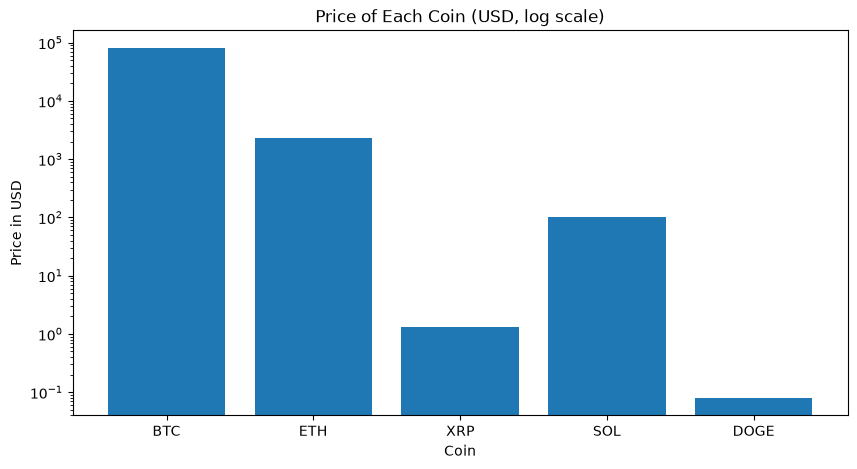

In [13]:
os.makedirs("charts", exist_ok=True)

plt.figure(figsize=(10, 5))
plt.bar(clean_df["symbol"], clean_df["price_usd"])
plt.yscale("log")
plt.title("Price of Each Coin (USD, log scale)")
plt.xlabel("Coin")
plt.ylabel("Price in USD")
plt.savefig("charts/price_by_coin.png")
plt.show()

24h change: green = up, red = down.

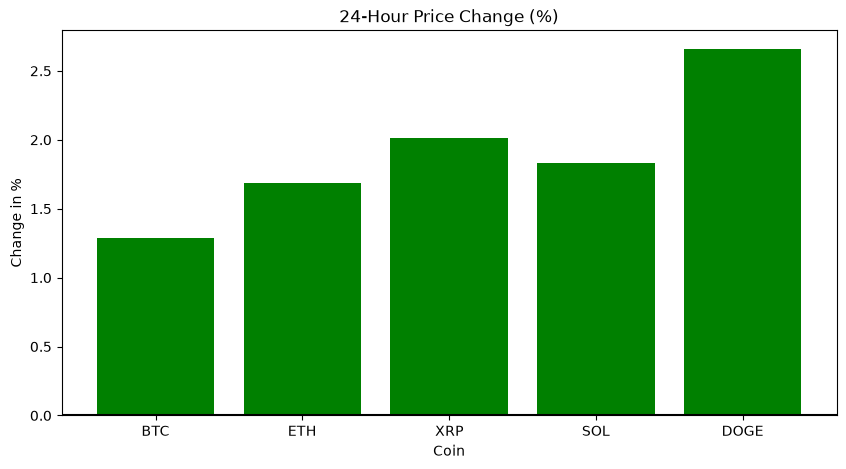

In [14]:
colors = []
for change in clean_df["percent_change_24h"]:
    if change >= 0:
        colors.append("green")
    else:
        colors.append("red")

plt.figure(figsize=(10, 5))
plt.bar(clean_df["symbol"], clean_df["percent_change_24h"], color=colors)
plt.axhline(0, color="black")
plt.title("24-Hour Price Change (%)")
plt.xlabel("Coin")
plt.ylabel("Change in %")
plt.savefig("charts/percent_change_24h.png")
plt.show()

Market cap share of each coin.

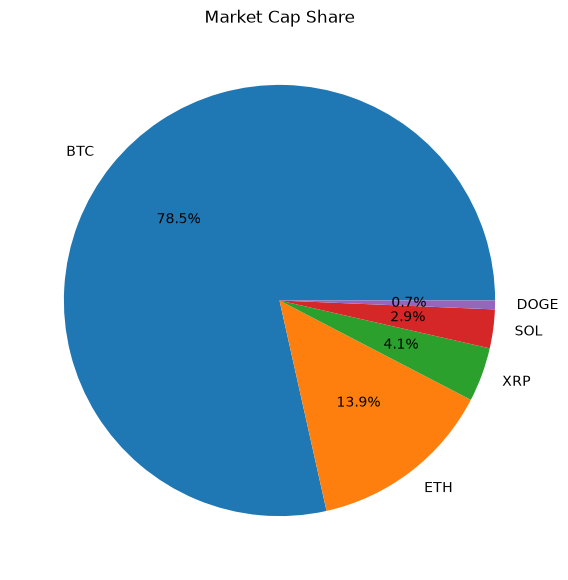

In [15]:
plt.figure(figsize=(7, 7))
plt.pie(clean_df["market_cap"], labels=clean_df["symbol"], autopct="%1.1f%%")
plt.title("Market Cap Share")
plt.savefig("charts/market_cap_share.png")
plt.show()

Price over time. Each notebook run adds a new point.

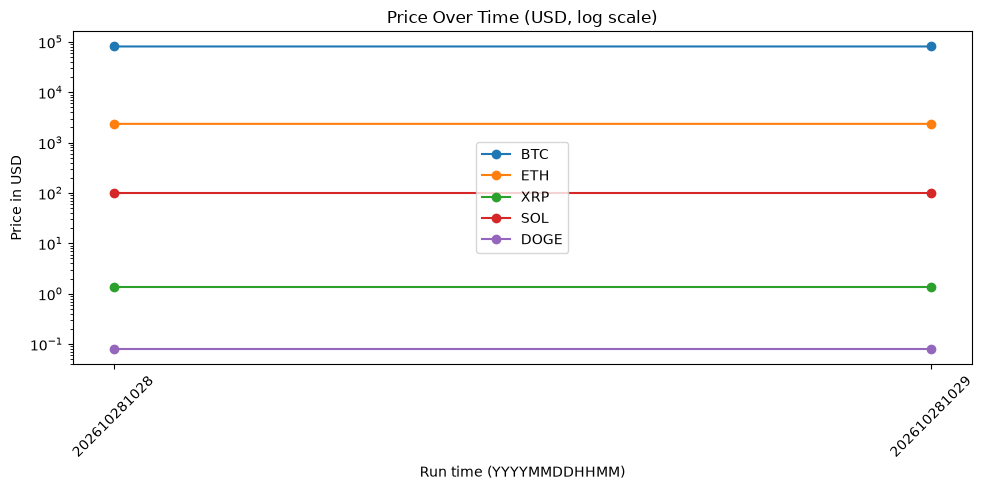

In [16]:
query = '''SELECT c.symbol, f.date_id, f.price_usd
           FROM fact_prices f JOIN dim_coin c ON f.coin_id = c.coin_id
           ORDER BY f.date_id'''
history_df = pd.read_sql_query(query, connection)
history_df["date_id"] = history_df["date_id"].astype(str)   # show date_id as text on the x-axis

plt.figure(figsize=(10, 5))
for symbol in clean_df["symbol"]:
    coin_history = history_df[history_df["symbol"] == symbol]
    plt.plot(coin_history["date_id"], coin_history["price_usd"], marker="o", label=symbol)
plt.yscale("log")
plt.title("Price Over Time (USD, log scale)")
plt.xlabel("Run time (YYYYMMDDHHMM)")
plt.ylabel("Price in USD")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("charts/price_over_time.png")
plt.show()

connection.close()
logging.info("Pipeline finished")

## 10. Summary
Got live data from an API, checked and cleaned it with Pandas, built a star schema,
loaded it into SQLite with no duplicates, checked it with SQL, and drew charts.

**Skills:** APIs, JSON, Pandas, data quality checks, star schema, SQL, SQLite, logging, matplotlib.